Author: Aparajita Nath

Product: credit modelling: training the model using a random forest

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import helpers as h

pd.set_option("display.max_columns", 30)

In [2]:
X_train, X_test, y_train, y_test = h.load_split()
categorical = h.categorical_columns(X_train)
print(X_train.shape, X_test.shape)

(700, 20) (300, 20)


## 3. Credit modelling

### 3.1 Tune the hyperparameters via GridSearchCV

Random forest: many decision trees fitted on random samples of the cases and inputs, with their predicted probabilities averaged. The number of trees is fixed at 300.

max_depth: [4, 6, 8, None]; min_samples_leaf: [3, 5, 10]; max_features: ['sqrt', 0.3]

The preprocessing is inside the pipeline, so it is refitted on the training part of every fold. The score is ROC-AUC from 5-fold cross-validation repeated 3 times, on the training set only.

In [3]:
pipe = Pipeline([("preprocess", h.make_preprocess(categorical)),
                 ("model", RandomForestClassifier(n_estimators=300, random_state=h.SEED))])
grid = {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [3, 5, 10],
        "model__max_features": ["sqrt", 0.3]}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=h.SEED)
search = GridSearchCV(pipe, param_grid=grid, cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_train, y_train)

print(f"Best cross-validated ROC-AUC: {search.best_score_:.3f}")
print("Best parameters:", search.best_params_)
cv_table = (pd.DataFrame(search.cv_results_)
            .loc[:, [c for c in search.cv_results_ if c.startswith("param_")] + ["mean_test_score", "std_test_score"]]
            .sort_values("mean_test_score", ascending=False).head(6))
cv_table.round(3)

Best cross-validated ROC-AUC: 0.789
Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}


,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,mean_test_score,std_test_score
19,None,sqrt,5,0.789,0.034
12,8,sqrt,3,0.787,0.033
18,None,sqrt,3,0.786,0.034
6,6,sqrt,3,0.786,0.037
13,8,sqrt,5,0.785,0.036
8,6,sqrt,10,0.785,0.035


### 3.2 Predict the PD on the held-out test set

In [4]:
model = search.best_estimator_
pd_test = model.predict_proba(X_test)[:, 1]

row = h.evaluate(y_test, pd_test, "Random forest")
pd.Series(row).drop("model").round(3).to_frame("Random forest")

,Random forest
roc_auc,0.789
auc_95ci_low,0.733
auc_95ci_high,0.842
gini,0.579
brier_score,0.167
mean_predicted_pd,0.31
observed_bad_rate,0.3


ROC-AUC and Gini (2 x AUC - 1) measure ranking. The Brier score measures the accuracy of the predicted probabilities. They are computed from the predicted probabilities, not from yes/no labels at a threshold.

### 3.3 Calibration of the PD

In [5]:
h.calibration_table(y_test, pd_test).round(3)

,cases,mean_predicted_pd,observed_bad_rate
score_bin,,,
Bin 1,60,0.114,0.050
Bin 2,60,0.210,0.117
Bin 3,60,0.300,0.350
Bin 4,60,0.397,0.333
Bin 5,60,0.532,0.650


### 3.4 Which inputs matter

Permutation importance on the test set: how much the ROC-AUC drops when one original input is shuffled. It is reported per original input (not per one-hot column) and, unlike the built-in impurity importance, is not biased towards inputs with many distinct values.

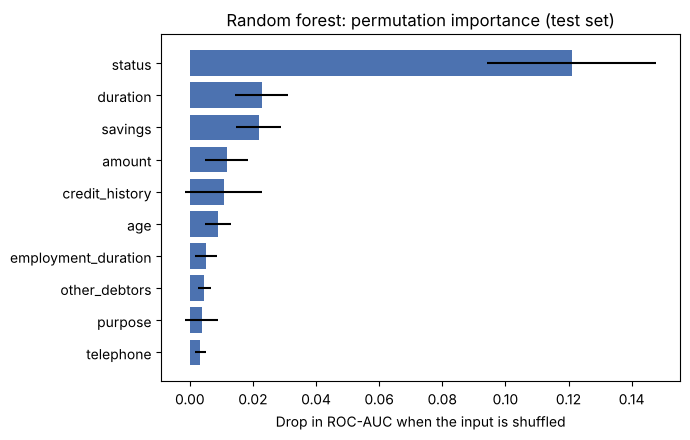

,mean_drop_in_auc,std
status,0.121,0.027
duration,0.023,0.008
savings,0.022,0.007
amount,0.012,0.007
credit_history,0.011,0.012
age,0.009,0.004
employment_duration,0.005,0.004
other_debtors,0.005,0.002
purpose,0.004,0.005
telephone,0.003,0.002


In [6]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                              random_state=h.SEED, n_jobs=-1)
imp = (pd.DataFrame({"mean_drop_in_auc": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns)
       .sort_values("mean_drop_in_auc", ascending=False))

top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top["mean_drop_in_auc"], xerr=top["std"], color="#4c72b0")
ax.set(xlabel="Drop in ROC-AUC when the input is shuffled", title="Random forest: permutation importance (test set)")
fig.tight_layout()
fig.savefig(h.FIGURES / "rf_permutation_importance.png", dpi=160)
plt.show()
imp.head(10).round(3)

### 3.5 Save the predictions and the fitted model for the comparison (D) and monitoring (E)

In [7]:
out = pd.DataFrame({"pd_pred": pd_test, "bad_credit": y_test.to_numpy()}, index=y_test.index)
out.to_csv(h.OUTPUTS / "preds_RF.csv")
joblib.dump(model, h.MODELS / "RF.joblib")
print("Saved predictions and model")

Saved predictions and model
